Basic ML (1 real input and 1 real output) - Polinomial regression + Regularization

In [135]:
import numpy as np # numerical things
import numpy.matlib as nml # matricial computations
import matplotlib.pyplot as plt # plots
from sklearn.model_selection import train_test_split

In [136]:
np.random.seed(15)

In [137]:
def oracle(x):
  return x**2
  #return np.sinc(3*x)
  #return np.abs(np.abs(x-.4)-.2) + x/2-.1

In [138]:
n = 50
sigma = 0.1 # we suppose we do not know nt

In [139]:
x = np.random.rand(n)
y = oracle(x) + sigma * np.random.randn(n)

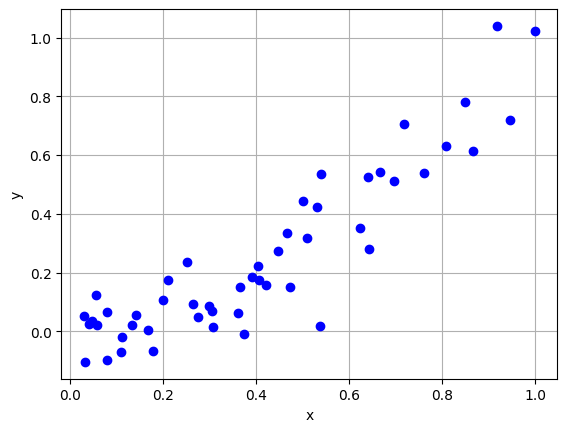

In [140]:
fig, ax = plt.subplots()
ax.plot(x,y, 'bo') # blue points
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.grid() # acrivate the grid
plt.show()

In [141]:
x = np.asmatrix(x).transpose()
y = np.asmatrix(y).transpose()

In [142]:
# Split the data in learning and validation
xl, xv, yl, yv = train_test_split(x, y, test_size=0.2)
nl = len(yl)
nv = len(yv)

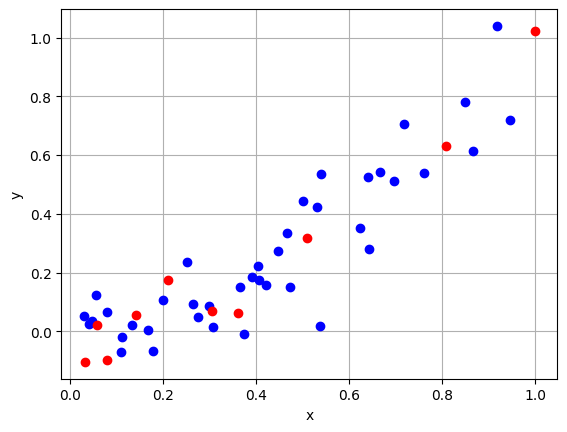

In [143]:
fig, ax = plt.subplots()
ax.plot(xl,yl, 'bo') # blue points to construct the model (learning)
ax.plot(xv,yv, 'ro') # red points to test the quality of the model (validation)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.grid() # acrivate the grid
plt.show()

'Division into learning and validation set with sigma = 0.0'

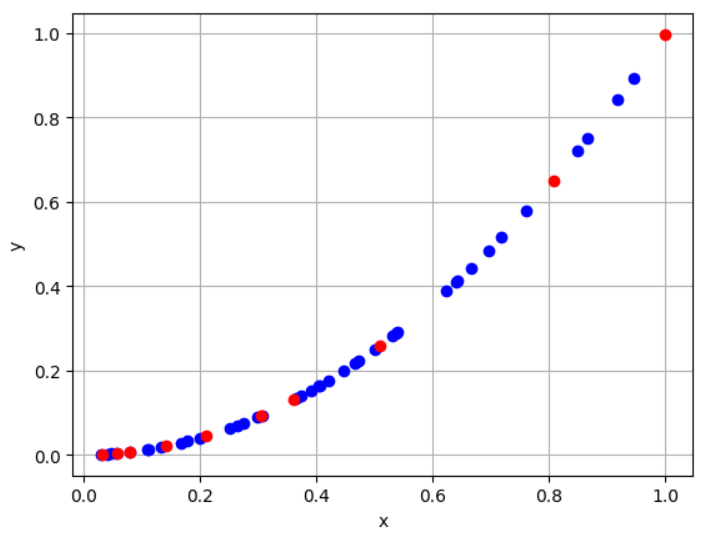

In [145]:
from IPython.display import Image, display
display("Division into learning and validation set with sigma = 0.0", Image(filename="/content/lear_val_sigma0.png", width=450))

In [144]:
# Choices I have to make:
# M - f'', |c|^2
# p
# lam
# -> I need to perform a greed search

err_best = +np.inf

for m in [0,1]:
  for p in range(0,14):
    for lam in np.logspace(-6,4,11):
      if (m==0):
        M = nml.zeros((p+1, p+1))

        for i in range(2, p+1):
          for j in range(2, p+1):
            M[i,j] = i * (i-1) * j * (j-1) / (i+j-3)
      else:
        M = nml.eye(p+1)

      X = nml.ones((nl,1))
      Xv = nml.ones((nv,1))

      for i in range (1, p+1):
        X = np.concatenate((X,np.power(xl,i)), axis=1)
        Xv = np.concatenate((Xv,np.power(xv,i)), axis=1)

      c = np.linalg.solve(X.T*X+lam*M, X.T*yl)
      yp = np.matmul(Xv,c)
      err = np.mean(np.power(yv-yp,2))

      if (err < err_best):
        err_best = err
        p_best = p
        m_best = m
        lam_best = lam
        yp_best = yp

print('p =', p_best)
print('m =', m_best)
print('lambda =', lam_best)

p = 4
m = 1
lambda = 0.1


Results
1. For the quadratic problem with n = 50 and sigma = 0.0:

    - no noise (sigma = 0)

    - best degree of the polynome is p = 2

    - It choses as best regularizer the Identity matrix and not the second degree of the polynome (m =  1)

    - As lambda it chooses a really small value (1e-06) -> reasonable because we do not have noise (we cannot fit it)

2. We add noise (n =  50, sigma =  0.1):

    I obtain different results from him (he gets p = 8, m = 0, lam = 1e-06; I get p = 4, m = 1, lam = 0.1). I will comment his ones.

      - The best solution is to use a very high degree of the polynome

      - The complexity measure is with m = 0

      - Small value of lambda

